In [ ]:
!pip -q install tensorflow==2.18.0 pandas numpy scikit-learn matplotlib

import os, math
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.5/615.5 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 41.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-decision-forests 1.12.0 requires tensorflow==2.19.0, but you have tensorflow 2.18.0 which is incompatible.
tensorflow-text 2.19.0 requires tensorflow<2.20,>=2.19.0, but you have tensorflow 2.18.0 which is incompatible.
tensorstore 0.1.78 requires ml_dtypes>=0.5.0, but you have ml-dtypes 0.4.1 which is incompatible.
tf-keras 2.19.0 requires tensorflow<2.20,>=2.19, but you have tensorflow 2.18.0 which is incompatible.
TF: 2.18.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import pandas as pd

df = pd.read_csv("/Battery_dataset.csv")

df.head()

,battery_id,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL
0,B5,1,1.440147,4.254682,23.988733,1.894407,3.273523,32.980834,1.986196,99.309790,219
1,B5,2,1.416595,4.159825,25.665347,1.829949,4.038741,32.257920,1.986240,99.311985,218
2,B5,3,1.420272,4.276323,25.407910,1.942105,3.214433,35.134801,1.984252,99.212608,217
3,B5,4,1.337680,4.236697,27.069757,2.073577,3.134529,32.082988,1.969236,98.461812,216
4,B5,5,1.263946,4.142791,26.478353,2.049885,3.729341,32.483154,1.974862,98.743106,215


In [ ]:
# Sort by cycle (important for time continuity)
df = df.sort_values(by=["battery_id", "cycle"])

# Drop id column
df = df.drop(columns=["battery_id"])

print(df.shape)
df.head()


(680, 10)


,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL
0,1,1.440147,4.254682,23.988733,1.894407,3.273523,32.980834,1.986196,99.309790,219
1,2,1.416595,4.159825,25.665347,1.829949,4.038741,32.257920,1.986240,99.311985,218
2,3,1.420272,4.276323,25.407910,1.942105,3.214433,35.134801,1.984252,99.212608,217
3,4,1.337680,4.236697,27.069757,2.073577,3.134529,32.082988,1.969236,98.461812,216
4,5,1.263946,4.142791,26.478353,2.049885,3.729341,32.483154,1.974862,98.743106,215


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df)
data_scaled = pd.DataFrame(data_scaled, columns=df.columns)
data_scaled.head()


,cycle,chI,chV,chT,disI,disV,disT,BCt,SOH,RUL
0,0.000000,0.588340,0.677465,0.256110,0.270841,0.419795,0.531390,0.993968,0.993968,0.879518
1,0.004016,0.556797,0.384837,0.436231,0.179901,0.827110,0.468747,0.994003,0.994003,0.875502
2,0.008032,0.561721,0.744226,0.408574,0.338137,0.388343,0.718038,0.992404,0.992404,0.871486
3,0.012048,0.451106,0.621981,0.587108,0.523626,0.345811,0.453588,0.980321,0.980321,0.867470
4,0.016064,0.352353,0.332290,0.523573,0.490199,0.662421,0.488264,0.984848,0.984848,0.863454


In [ ]:
import numpy as np

SEQ_LEN = 20  # number of timesteps per sequence (you can tune)
STEP = 1

def make_sequences(data, seq_len=SEQ_LEN, step=STEP):
    sequences = []
    for i in range(0, len(data) - seq_len, step):
        seq = data.iloc[i:i+seq_len].values
        sequences.append(seq)
    return np.array(sequences, dtype=np.float32)

real_data = make_sequences(data_scaled)
print("Shape of training data:", real_data.shape)


Shape of training data: (660, 20, 10)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import layers, models, optimizers

# ===============================
# DROP cycle (CRITICAL)
# ===============================
df_gan = df.drop(columns=["cycle"])

# ===============================
# Scaling
# ===============================
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df_gan)
data_scaled = pd.DataFrame(data_scaled, columns=df_gan.columns)

# ===============================
# Create sequences
# ===============================
SEQ_LEN = 20
STEP = 1

def make_sequences(data, seq_len=SEQ_LEN, step=STEP):
    sequences = []
    for i in range(0, len(data) - seq_len, step):
        sequences.append(data.iloc[i:i+seq_len].values)
    return np.array(sequences, dtype=np.float32)

real_data = make_sequences(data_scaled)

N, T, F = real_data.shape
print("Real data shape:", real_data.shape)



Real data shape: (660, 20, 9)


In [ ]:
HIDDEN_DIM = 24
BATCH_SIZE = 64
LR = 1e-4

EPOCHS_EMB = 500
EPOCHS_SUP = 300
EPOCHS_GAN = 1200

NOISE_STD = 1.7   # ✅ balanced noise


In [ ]:
dataset = (
    tf.data.Dataset
    .from_tensor_slices(real_data)
    .batch(BATCH_SIZE, drop_remainder=True)
)


In [ ]:
mse = tf.keras.losses.MeanSquaredError()
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

opt_embedder = optimizers.Adam(LR)
opt_supervisor = optimizers.Adam(LR)
opt_generator = optimizers.Adam(LR)
opt_discriminator = optimizers.Adam(LR)


In [ ]:
def make_rnn(hidden=HIDDEN_DIM):
    return layers.GRU(hidden, return_sequences=True)

embedder = make_rnn()

recovery = models.Sequential([
    make_rnn(),
    layers.TimeDistributed(layers.Dense(F, activation="sigmoid"))
])

generator = make_rnn()
supervisor = make_rnn()

discriminator = models.Sequential([
    layers.GRU(64, return_sequences=True),
    layers.GRU(64),
    layers.Dense(1)
])


In [ ]:
@tf.function
def train_embedder(x):
    with tf.GradientTape() as tape:
        h = embedder(x)
        x_tilde = recovery(h)
        loss = mse(x, x_tilde)

    vars_ = embedder.trainable_variables + recovery.trainable_variables
    opt_embedder.apply_gradients(
        zip(tape.gradient(loss, vars_), vars_)
    )
    return loss

print("\nPhase 1: Embedder Training")
for epoch in range(EPOCHS_EMB):
    losses = [train_embedder(x).numpy() for x in dataset]
    if epoch % 100 == 0:
        print(f"[Embedder] Epoch {epoch} | Recon={np.mean(losses):.4f}")



Phase 1: Embedder Training
[Embedder] Epoch 0 | Recon=0.0415
[Embedder] Epoch 100 | Recon=0.0202
[Embedder] Epoch 200 | Recon=0.0157
[Embedder] Epoch 300 | Recon=0.0117
[Embedder] Epoch 400 | Recon=0.0081


In [ ]:
embedder.trainable = False
recovery.trainable = False

@tf.function
def train_supervisor(x):
    with tf.GradientTape() as tape:
        h = embedder(x)
        h_hat = supervisor(h)
        loss = mse(h[:, 1:, :], h_hat[:, :-1, :])

    opt_supervisor.apply_gradients(
        zip(tape.gradient(loss, supervisor.trainable_variables),
            supervisor.trainable_variables)
    )
    return loss

print("\nPhase 2: Supervisor Training")
for epoch in range(EPOCHS_SUP):
    losses = [train_supervisor(x).numpy() for x in dataset]
    if epoch % 100 == 0:
        print(f"[Supervisor] Epoch {epoch} | SupLoss={np.mean(losses):.4f}")



Phase 2: Supervisor Training
[Supervisor] Epoch 0 | SupLoss=0.2235
[Supervisor] Epoch 100 | SupLoss=0.0175
[Supervisor] Epoch 200 | SupLoss=0.0111


In [ ]:
embedder.trainable = True
recovery.trainable = True

@tf.function
def train_gan(x):
    z = tf.random.normal((BATCH_SIZE, T, HIDDEN_DIM), stddev=NOISE_STD)

    with tf.GradientTape(persistent=True) as tape:
        # Real
        h = embedder(x)

        # Fake
        e_hat = generator(z)
        h_hat = supervisor(e_hat)
        x_hat = recovery(h_hat)

        y_real = discriminator(h)
        y_fake = discriminator(h_hat)

        real_labels = tf.ones_like(y_real) * 0.9
        fake_labels = tf.zeros_like(y_fake) + 0.1

        recon_loss = mse(x, recovery(h))
        sup_loss = mse(h[:, 1:, :], supervisor(h)[:, :-1, :])

        # ✅ FIXED LOSS BALANCE
        g_loss = (
            bce(tf.ones_like(y_fake), y_fake)
            + 3 * sup_loss          # ↓↓↓ critical fix
            + 2 * mse(x, x_hat)
        )

        d_loss = (
            bce(real_labels, y_real) +
            bce(fake_labels, y_fake)
        )

    vars_g = generator.trainable_variables + supervisor.trainable_variables
    vars_d = discriminator.trainable_variables
    vars_e = embedder.trainable_variables + recovery.trainable_variables

    opt_generator.apply_gradients(zip(tape.gradient(g_loss, vars_g), vars_g))
    opt_generator.apply_gradients(zip(tape.gradient(g_loss, vars_g), vars_g))

    if d_loss > 0.1:
        grads_d = [tf.clip_by_norm(g, 1.0)
                   for g in tape.gradient(d_loss, vars_d)]
        opt_discriminator.apply_gradients(zip(grads_d, vars_d))

    opt_embedder.apply_gradients(
        zip(tape.gradient(recon_loss, vars_e), vars_e)
    )

    return recon_loss, g_loss, d_loss


In [ ]:
print("\nPhase 3 & 4: GAN Training")
for epoch in range(EPOCHS_GAN):
    recs, gs, ds = [], [], []
    for x in dataset:
        r, g, d = train_gan(x)
        recs.append(r.numpy())
        gs.append(g.numpy())
        ds.append(d.numpy())

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Recon={np.mean(recs):.4f} | "
            f"G={np.mean(gs):.4f} | "
            f"D={np.mean(ds):.4f}"
        )



Phase 3 & 4: GAN Training
Epoch    0 | Recon=0.0056 | G=0.8257 | D=1.3793
Epoch  100 | Recon=0.0037 | G=0.3482 | D=2.0021
Epoch  200 | Recon=0.0021 | G=0.4768 | D=1.6416
Epoch  300 | Recon=0.0013 | G=0.4560 | D=1.6406
Epoch  400 | Recon=0.0009 | G=0.7597 | D=1.3361
Epoch  500 | Recon=0.0008 | G=0.8788 | D=1.3557
Epoch  600 | Recon=0.0007 | G=1.4298 | D=1.0205
Epoch  700 | Recon=0.0006 | G=2.1782 | D=0.6707
Epoch  800 | Recon=0.0005 | G=1.0811 | D=1.2912
Epoch  900 | Recon=0.0005 | G=2.2241 | D=1.0436
Epoch 1000 | Recon=0.0004 | G=3.3339 | D=0.6522
Epoch 1100 | Recon=0.0004 | G=2.6850 | D=0.6528


In [ ]:
def sample_synthetic(n_samples):
    z = tf.random.normal((n_samples, T, HIDDEN_DIM), stddev=NOISE_STD)
    e_hat = generator(z)
    h_hat = supervisor(e_hat)
    x_hat = recovery(h_hat)
    return x_hat.numpy()

synthetic_data = sample_synthetic(len(real_data))
print("Synthetic shape:", synthetic_data.shape)

np.save("/content/synthetic_battery_sequences.npy", synthetic_data)
print("Saved synthetic data.")


Synthetic shape: (660, 20, 9)
Saved synthetic data.


Synthetic data shape: (660, 20, 9)
Synthetic data shape: (660, 20, 9)


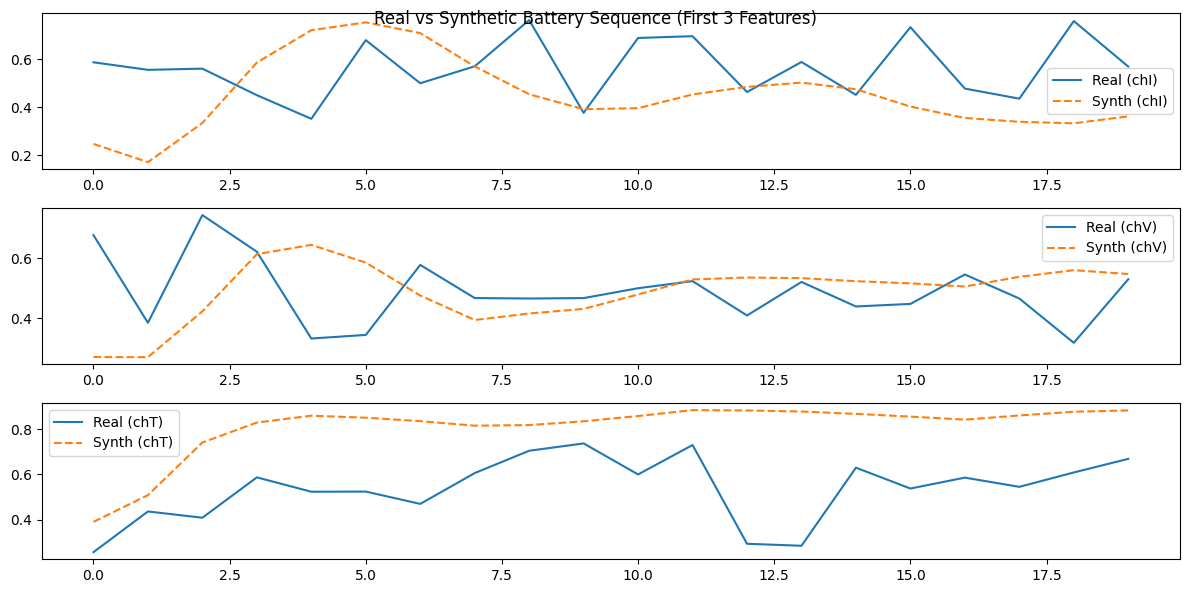

✅ Synthetic data saved to: /content/synthetic_battery_sequences.npy


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ---- Generate synthetic sequences ----
def sample_synthetic(n_samples):
    z = tf.random.normal((n_samples, T, HIDDEN_DIM))
    e_hat = generator(z)
    h_hat = supervisor(e_hat)
    x_hat = recovery(h_hat)
    return x_hat.numpy()

# Generate same number of synthetic sequences as real ones
synthetic_data = sample_synthetic(len(real_data))
print("Synthetic data shape:", synthetic_data.shape)
import matplotlib.pyplot as plt
import numpy as np

# ---- Generate synthetic sequences ----
def sample_synthetic(n_samples):
    z = tf.random.normal((n_samples, T, HIDDEN_DIM))
    e_hat = generator(z)
    h_hat = supervisor(e_hat)
    x_hat = recovery(h_hat)
    return x_hat.numpy()

# Generate same number of synthetic sequences as real ones
synthetic_data = sample_synthetic(len(real_data))
print("Synthetic data shape:", synthetic_data.shape)

# ---- Compare one real vs one synthetic sequence visually ----
feature_names = df.columns.tolist()[1:]  # skip battery_id if dropped earlier

plt.figure(figsize=(12, 6))
for i in range(min(3, synthetic_data.shape[2])):  # plot first 3 features
    plt.subplot(3, 1, i+1)
    plt.plot(real_data[0, :, i], label=f"Real ({feature_names[i]})")
    plt.plot(synthetic_data[0, :, i], '--', label=f"Synth ({feature_names[i]})")
    plt.legend(loc='best')
    plt.tight_layout()
plt.suptitle("Real vs Synthetic Battery Sequence (First 3 Features)")
plt.show()

# ---- Save for later RUL modelling ----
np.save("/content/synthetic_battery_sequences.npy", synthetic_data)
print("✅ Synthetic data saved to: /content/synthetic_battery_sequences.npy")

Real data shape: (660, 20, 9)
Synthetic data shape: (660, 20, 9)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


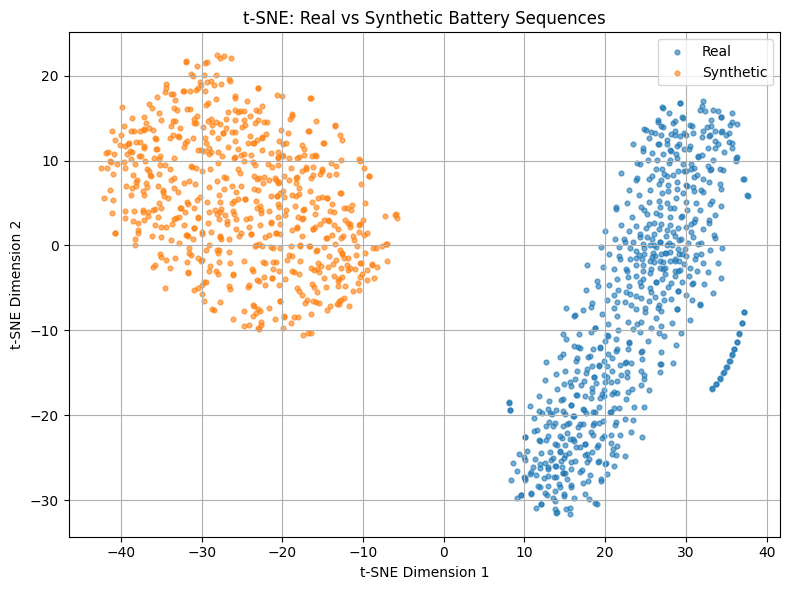

In [ ]:
# ======================================================
# t-SNE: Real vs Synthetic Time-Series (TimeGAN)
# ======================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------
# Assumptions:
# real_data      -> shape (N, T, F)
# synthetic_data -> shape (N, T, F)
# cycle column already removed before GAN training
# ------------------------------------------------------

# --------------------
# Shapes
# --------------------
N_real, T, F = real_data.shape
N_synth = synthetic_data.shape[0]

print("Real data shape:", real_data.shape)
print("Synthetic data shape:", synthetic_data.shape)

# --------------------
# Flatten sequences
# --------------------
# Each sequence becomes a single vector (T * F)
real_flat = real_data.reshape(N_real, T * F)
synth_flat = synthetic_data.reshape(N_synth, T * F)

# --------------------
# Combine real + synthetic
# --------------------
X = np.vstack([real_flat, synth_flat])
labels = np.array(
    ["Real"] * N_real + ["Synthetic"] * N_synth
)

# --------------------
# Standardize (IMPORTANT)
# --------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------
# Run t-SNE
# --------------------
tsne = TSNE(
    n_components=2,
    perplexity=30,
    n_iter=1000,
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

# --------------------
# Split back
# --------------------
real_tsne = X_tsne[labels == "Real"]
synth_tsne = X_tsne[labels == "Synthetic"]

# --------------------
# Plot
# --------------------
plt.figure(figsize=(8, 6))

plt.scatter(
    real_tsne[:, 0],
    real_tsne[:, 1],
    s=12,
    alpha=0.6,
    label="Real"
)

plt.scatter(
    synth_tsne[:, 0],
    synth_tsne[:, 1],
    s=12,
    alpha=0.6,
    label="Synthetic"
)

plt.title("t-SNE: Real vs Synthetic Battery Sequences")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

synthetic_data = np.load("/content/synthetic_battery_sequences.npy")
print(synthetic_data.shape)


(660, 20, 9)
